## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams. 

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [1]:
import pickle

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
    
from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

Plot a histogram of the occurrences of tokens. 
What do you notice about the frequency of occurrence of different tokens? How does it look?

**Q2.** 

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions? 

**Q3.** 

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Roshan Mahesh

**Date:** 10/15/2026

Unique tokens: 48691
Share appearing exactly once: 0.604


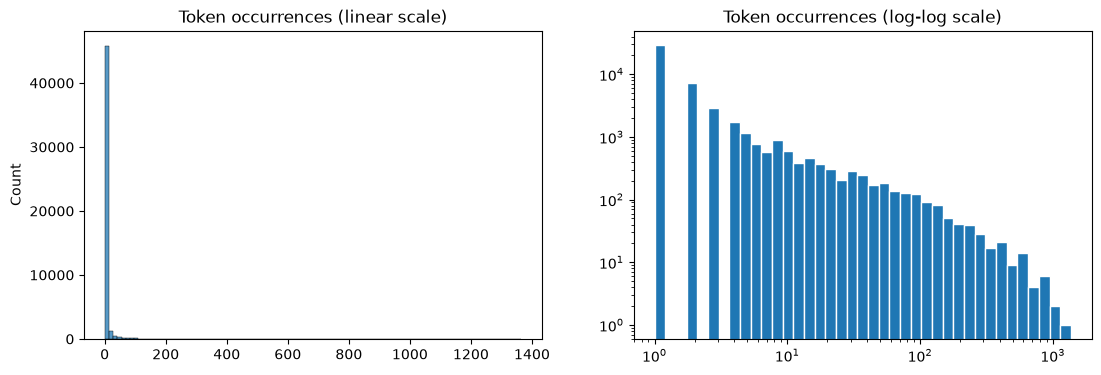

Train R^2: 0.766
Test R^2: 0.6702
                  token      coef  abs_coef
1504  background-image: -1.201203  1.201203
740           localized  0.815112  0.815112
906               aging  0.735023  0.735023
2362            thermal  0.590412  0.590412
1406         helvetica,  0.587472  0.587472
835        intervention -0.580474  0.580474
1302           erectile  0.575784  0.575784
1511            burning -0.569225  0.569225
1839              form.  0.560255  0.560255
2559            april's -0.525984  0.525984
818                cnet -0.495563  0.495563
2532             xanaax  0.490234  0.490234
2657              zdnet -0.487835  0.487835
1256             arial, -0.483577  0.483577
2365                rcs  0.464646  0.464646


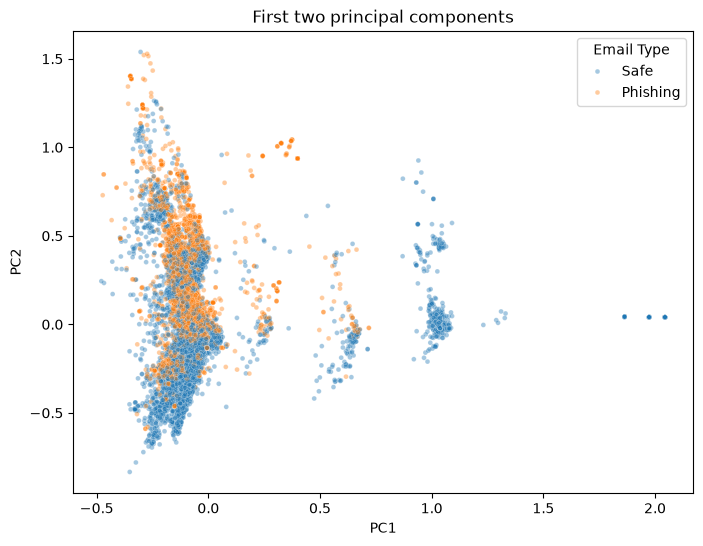

Train R^2: 0.7651
Test R^2: 0.6718


In [2]:
# Your Phase 1 solution to the problem goes here.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
#converts the token frequency list into a Series of token counts
counts = pd.Series(dict(token_freq))
#prints summary stats on how often tokens appear
print('Unique tokens:', len(counts))
print('Share appearing exactly once:', round((counts == 1).mean(), 3))
#plots histograms of token occurrences on a linear scale and a log-log scale
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(counts, bins=100, ax=axes[0])
axes[0].set_title('Token occurrences (linear scale)')
log_bins = np.logspace(0, np.log10(counts.max()), 40)
axes[1].hist(counts, bins=log_bins, edgecolor='white')
axes[1].set_xscale('log')
axes[1].set_yscale('log')
axes[1].set_title('Token occurrences (log-log scale)')
plt.show()
#Answer: The distribution is extremely right-skewed, with about 60% of tokens appearing only once while a few words like "new" and "enron" appear over 900 times, forming a nearly straight line on a log-log plot (Zipf's law).
#Q2
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

#loads the email data and separates the outcome from the token features
df = pd.read_parquet('data/Phishing_clean.parquet')
y = df['Email Type']
X = df.drop(columns='Email Type')

#performs an 80/20 train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=125)
#fits a linear regression on the tokens and prints train and test R^2
lm = LinearRegression().fit(X_train, y_train)
print('Train R^2:', round(lm.score(X_train, y_train), 4))
print('Test R^2:', round(lm.score(X_test, y_test), 4))
#ranks tokens by the absolute value of their coefficients
coefs = pd.DataFrame({'token': X.columns, 'coef': lm.coef_})
coefs['abs_coef'] = coefs['coef'].abs()
print(coefs.sort_values('abs_coef', ascending=False).head(15))
#Answer: The test R^2 is about 0.67 and the train R^2 is about 0.77, and the most influential words are "background-image:", "localized", "aging", "thermal", "helvetica,", "intervention", and "erectile".

#Q3
from sklearn.decomposition import PCA

#runs PCA with two components on the token matrix
pca2 = PCA(n_components=2)
Z2 = pca2.fit_transform(X)

#builds a dataframe of the two components labeled by email type
pc_df = pd.DataFrame(Z2, columns=['PC1', 'PC2'])
pc_df['Email Type'] = y.map({0: 'Safe', 1: 'Phishing'}).values

#plots PC1 vs PC2 colored by whether the email is phishing
plt.figure(figsize=(8, 6))
sns.scatterplot(data=pc_df, x='PC1', y='PC2', hue='Email Type', alpha=0.4, s=12)
plt.title('First two principal components')
plt.show()

#Answer: Phishing emails mostly sit higher on PC2 and safe emails spread out more along PC1, but there's a lot of overlap in the middle.

#Q4
#fits PCA with 2,610 components on the training set and transforms both sets
pca = PCA(n_components=2610)
Z_train = pca.fit_transform(X_train)
Z_test = pca.transform(X_test)

#fits a linear regression on the principal components and prints train and test R^2
lm_pc = LinearRegression().fit(Z_train, y_train)
print('Train R^2:', round(lm_pc.score(Z_train, y_train), 4))
print('Test R^2:', round(lm_pc.score(Z_test, y_test), 4))

#Answer: Train R^2 is about 0.765 and test is about 0.672, so it does basically the same as the regular regression.

#Q5
#Answer: The components aren't correlated with each other, so the regression is more stable and you can drop the noisy ones to avoid overfitting.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [3]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]